In [11]:
from glob import glob

# 사용할 PDF 파일 확인하기
for g in glob('../data/*.pdf'):
    print(g)


../data\2040_seoul_plan.pdf
../data\OneNYC_2050_Strategic_Plan.pdf


In [12]:
# read_pdf_and_split_text 함수 생성: PDF 파일을 텍스트로 읽고 청크 단위로 텍스트를 잘라 리스트를 담아 반환
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

def read_pdf_and_split_text(pdf_path, chunk_size=1000, chunk_overlap=100):
    """
    주어진 PDF 파일을 읽고 텍스트를 분할합니다.

    매개변수:
        pad_path (str): PDF 파일의 경로
        chunk_size (int, 선택적): 각 텍스트 청크의 크기, 기본값은 1000
        chunk_overlap (int, 선택적): 청크 간 중복 문자 수, 기본값은 100
    반환값:
        list: 분할된 텍스트 청크의 리스트
    """
    print(f"PDF: {pdf_path}------------------------")
    
    pdf_loader = PyPDFLoader(pdf_path)
    data_from_pdf = pdf_loader.load()

    text_splitter = RecursiveCharacterTextSplitter(chunk_size=chunk_size, chunk_overlap=chunk_overlap)
    splits = text_splitter.split_documents(data_from_pdf)

    print(f"Number of chunks: {len(splits)}\n")
    return splits

In [12]:
# vectorstore 설정하고 청크 처리하기
from langchain_openai import OpenAIEmbeddings
from langchain_chroma import Chroma
import os

##### veectorstore 설정 #####
embedding = OpenAIEmbeddings(model="text-embedding-3-large")

persist_directory='../chroma_store'

if os.path.exists(persist_directory):
    print('Loading existing Chroma store')
    vectorstore = Chroma(persist_directory=persist_directory, embedding_function=embedding)

else:
    print("Creating new Chroma store")

    vectorstore = None
    for g in glob('../data/*.pdf'):
        chunks = read_pdf_and_split_text(g)
        # 100 개씩 나눠서 저장
        for i in range(0, len(chunks), 100):
            if vectorstore is None:
                vectorstore = Chroma.from_documents(
                    documents=chunks[i:i+100],
                    embedding=embedding,
                    persist_directory=persist_directory
                )
            else:
                vectorstore.add_documents(
                    documents=chunks[i:i+100],
                )

Loading existing Chroma store


In [13]:
# 관련 문서 검색하기
retriever = vectorstore.as_retriever(search_kwargs={"k": 3})

chunks = retriever.invoke("서울 온실가스 저감 계획")

for chunk in chunks:
    print(chunk.metadata)
    print(chunk.page_content)
    print("--------------------------------")

{'producer': 'Hancom PDF 1.3.0.542', 'source': '../data\\2040_seoul_plan.pdf', 'creator': 'Hwp 2020 11.0.0.5178', 'creationdate': '2024-12-12T18:16:11+09:00', 'pdfversion': '1.4', 'moddate': '2024-12-12T18:16:11+09:00', 'author': 'SI', 'total_pages': 205, 'page': 63, 'page_label': '64'}
56제2장 미래상과 목표
6. 미래위기를 준비하는, ‘탄소중립 안전도시 구축’1) 배경전(全) 지구적인 기후변화에 대응하기 위한 대도시 차원의 대응 필요Ÿ서울시 2017년 온실가스 배출량은 46,685천 톤CO2eq로 2005년 배출량에 비해 5.6%(276만 톤CO2eq) 감소하였으며, 서울의 1인당 온실가스 배출량은 4.7CO2eq로 국가의 13.8톤CO2eq에 비해 낮은 수준이다. 또한 2014년 기준 서울의 1인당 온실가스 배출량은 4.5CO2eq로 세계 주요 도시에 비해 낮은 수준을 보인다.7)
[그림 2-26] 세계 주요 도시 1인당 온실가스 배출량   자료: World Bank, 2014Ÿ그럼에도 불구하고, 기후변화 문제는 21세기에 전 지구적으로 가장 위중한 영향을 미칠 것으로 예상되는바, 탄소중립과 기후위기 대응은 국제·국가·도시의 핵심 정책으로 다루어져야 한다.Ÿ파리협정(2015) 이후, 우리나라를 비롯한 미국, 유럽연합 등 세계 136개국이 탄소중립을 선언하였으며, 서울시를 비롯한 뉴욕, 런던 등과 같은 많은 글로벌 도시에서 탄소중립을 시정의 핵심과제로 추진 중이다.Ÿ우리나라는 2020년 ‘한국판 그린뉴딜’을 발표하며 공식적으로 2050 탄소중립을 선언하였으며 서울시 역시 2020년 ‘그린뉴딜 추진을 통한 2050 온실가스 감축 전략’을 발표하고 탄소중립 선언에 따른 부문별 사업을 적극 추진하고 있다.-서울시는 2050년 탄소중립을 목

In [3]:
# 챗봇으로 활용하기 위한 언어 모델 설정
from langchain_openai import ChatOpenAI

# 모델 초기화
model = ChatOpenAI(model="gpt-4o-mini", temperature=0)
model.invoke("안녕하세요.")

AIMessage(content='안녕하세요! 어떻게 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 10, 'prompt_tokens': 10, 'total_tokens': 20, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_197a02a720', 'id': 'chatcmpl-C0jwUbS66dZBy9v1UE2dBxDYFSxL8', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='run--0a8fcc5b-0ebd-4b48-beea-f628a0377372-0', usage_metadata={'input_tokens': 10, 'output_tokens': 10, 'total_tokens': 20, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

In [4]:
# 라우터 설정하기
from langchain_core.prompts import ChatPromptTemplate
from typing import Literal # 문자열 리터럴 타입을 지원하는 typing 모듈
from pydantic import BaseModel, Field

# Data model
class RouteQuery(BaseModel):
    """사용자 쿼리를 가장 관련성이 높은 데이터 소스로 라우트 합니다."""
    
    datasource: Literal["vectorstore", "casual_talk"] = Field(
        '''
        description="""
            사용자 질문에 따라 casual_talk 또는 vectorestore 로 라우팅 하니다."casual_talk"
            - casual_talk: 일상 대화를 위한 데이터 소스. 사용자가 일상적인 질문을 할 때 사용합니다.
            - vectorstore: 사용자 질문에 답하기 위해 RAG 로 vectorstore 검색이 필요한 경우 사용합니다.
        """
        '''
    )

In [5]:
# 사용자 질문을 받고 판단하기
structured_llm_router = model.with_structured_output(RouteQuery)

router_system = """
당신은 사용자의 질문을 vectorestore 또는 casual_talk 로 라우팅하는 전문가입니다.
- vectorstore 에는 서울, 뉴욕의 발전계획과 관련된 문서가 포함되어 있습니다. 이 주제에 대한 질문에는 vectorstore를 사용하십시오.
- 사용자의 질문이 일상 대화에 관련된 경우 casual_talk 을 사용하십시오.
"""

# 시스템 메시지와 사용자의 질문을 포함하는 프롬프트 템플릿 생성
route_prompt = ChatPromptTemplate.from_messages([
    ("system", router_system),
    ("human", "{question}")
])

# 라우터 프롬프트와 구조화된 출력 모델을 결합한 객체
question_router = route_prompt | structured_llm_router

In [6]:
# 결과 출력하기
print(
    question_router.invoke(
        {
            "question": "서울 온실가스 저감 계획에 대해 알려줘"
        }
    )
)

print(question_router.invoke(
    {
        "question": "잘 지냈어?"
    }
))

datasource='vectorstore'
datasource='casual_talk'


In [9]:
# GradeDocumentes 클래스 만들기 : 출력 방식을 yes 또는 no 로만 제한하여 문서의 관련성 판단
from langchain_core.prompts import PromptTemplate

class GradeDocuments(BaseModel):
    """검색된 문서가 질문과 관련성 있는지 yes 또는 no로 평가합니다"""

    binary_score: Literal["yes", "no"] = Field(
        description="문서가 질문과 관련이 있는지 여부를 'yes' 또는 'no'로 평가합니다."
    )

structured_llm_router = model.with_structured_output(GradeDocuments)

In [14]:
# 프롬프트 작성하고 테스트하기
# 단순 프롬프트라 ChatPromprtTempate 안써도 됨
grader_prompt = PromptTemplate.from_template("""
    당신은 검색된 문서가 사용자 질문과 관련이 있는지 평가하는 평가자입니다. \n
    문서에 사용자 질문과 관련된 키워드 또는 의미가 포함되어 있으면, 해당 문서를 관련성이 있다고 평ㄱ아하십시오. \n
    엄격한 테스트가 필요하지 않습니다. 목표는 잘못된 검색 결과를 걸러내는 것입니다. \n
    문서가 질문과 관련이 있는지 여부를 나타내기 위해 'yes' 또는 'no'로 이진 점수를 부여하십시오. \n

    Retrieved document: \n {document} \n
    User question: \n {question} \n
""")

retrieval_grader = grader_prompt | structured_llm_router
question = "서울시 자율주행 관련 계획"
documents = retriever.invoke(question)

for doc in documents:
    print(doc)

page_content='54제2장 미래상과 목표
5. 기술발전에 선제적 대응, ‘미래교통 인프라 구축’1) 배경미래교통수단 도입에 따른 도시 활동 변화 및 공간구조 재편 대비Ÿ빠르게 진화하는 미래 신 교통수단은 도시공간에 새로운 변화를 일으킬 것이며, 도시 내 이동패턴의 변화를 가져올 것으로 예측된다. 이러한 점을 고려하여 도시 내 다양한 통행행태가 공존하는 포용적인 교통체계 구축을 준비해야 한다.미래교통수단 정착을 위한 도시 인프라 확충지원 필요Ÿ기존에 없던 새로운 교통은 통상 인프라 구축에 많은 시간이 소요되기 때문에 교통수단이 도입된 이후에 준비하기보다는 개발단계에서부터 이를 지원하기 위한 교통인프라 구축 구상이 요구되며, 새로운 도시 인프라 확충에 대한 도시계획적 지원이 필요하다.2) 추진전략자율주행 자동차 본격 운영 체계 구축Ÿ자율주행은 현재 제일 가시화되고 있는 미래 교통기술로 시장의 주도권을 확보하기 위해 각국의 노력이 집중되고 있다. 단계적으로 2030년까지 간선도로급 이상 도로에서 운영할 수 있는 도로 인프라 환경을 조성하고, 2040년까지 서울 전역 자율주행 운행 환경 구축을 목표로 한다.-2040년까지 서울 전역 자율주행차량의 운행 환경을 구축하고 수송 분담률 10%를 달성서울형 도심 항공교통 기반 마련 및 터미널 확충Ÿ도심에서 김포공항까지 시범노선을 운영하는 등 상용화 노선을 확보하고, 장기적으로 한강, 지천 등 주요 수변 공간 중심으로 광역노선을 확보한다. 또한 UAM 인프라 확보를 위한 인센티브 및 도시계획적인 지원 방안도 함께 검토한다.-UAM 시범노선을 운영하고, 한강 등 주요 수변 공간 중심에 단계적 광역노선을 확장서울 전역에 모빌리티 허브 구축Ÿ도심 및 광역거점에 서울 내부와 외부의 연계를 위한 미래 교통과 기존 교통을 연결하는 시설을 도입한다. 또한 교통뿐 아니라 공공서비스, 물류, 상업 등 다양한 기능들이 복합적으로 제공되는 지역 거점 모빌리티 허브를 서울 전역에 도입한다.' metadata={'page_label': '6

In [15]:
# 관련된 청크만 리스트에 추가하기
filtered_docs = []

for i, doc in enumerate(documents):
    print(f'Document {i+1}: {doc.metadata}')
    is_relevant = retrieval_grader.invoke({
        "document": doc.page_content,
        "question": question
    })
    print(is_relevant)
    print(doc.page_content[:200])
    print("==============================\n\n")

    if is_relevant.binary_score == "yes":
        filtered_docs.append(doc)

print(f'Filtered {len(filtered_docs)} documents out of {len(documents)}')


Document 1: {'page_label': '62', 'total_pages': 205, 'source': '../data\\2040_seoul_plan.pdf', 'pdfversion': '1.4', 'creator': 'Hwp 2020 11.0.0.5178', 'page': 61, 'author': 'SI', 'creationdate': '2024-12-12T18:16:11+09:00', 'moddate': '2024-12-12T18:16:11+09:00', 'producer': 'Hancom PDF 1.3.0.542'}
binary_score='yes'
54제2장 미래상과 목표
5. 기술발전에 선제적 대응, ‘미래교통 인프라 구축’1) 배경미래교통수단 도입에 따른 도시 활동 변화 및 공간구조 재편 대비Ÿ빠르게 진화하는 미래 신 교통수단은 도시공간에 새로운 변화를 일으킬 것이며, 도시 내 이동패턴의 변화를 가져올 것으로 예측된다. 이러한 점을 고려하여 도시 내 다양한 통행행태가 공존하는 포용적인 교통체계 구


Document 2: {'page_label': '44', 'producer': 'Hancom PDF 1.3.0.542', 'total_pages': 205, 'creator': 'Hwp 2020 11.0.0.5178', 'moddate': '2024-12-12T18:16:11+09:00', 'pdfversion': '1.4', 'creationdate': '2024-12-12T18:16:11+09:00', 'source': '../data\\2040_seoul_plan.pdf', 'page': 43, 'author': 'SI'}
binary_score='yes'
36제2장 미래상과 목표
6) 미래교통수단의 등장과 첨단 인프라 요구 증대자율주행, UAM 등 미래 교통에 공간적 대응방안 마련 필요Ÿ자율주행차량, 전동킥보드 등 교통 기술의 발전에 따라 새로운 교통환경이 조성되고 있음에도 불구하고, 이에 대한 정착 가이드라인이 없어, 위험한 교통 사

In [16]:
# RAG 답변 생성하기
# RAG 를 위한 프롬프트 생성하기

### Generate
# PromptTemplate 을 사용해 RAG 를 위한 프롬프트 생성

rag_generate_system = """
너는 사용자의 질문에 대해 주어진 context 에 기반하여 답변하는 도시 계획 전문가이다.
주어진 context 는 vectorstore에서 검색된 결과이다.
주어진 context를 기반으로 사용자의 question에 대해 답변하라.

=========================================
question: {question}
context: {context}
=========================================
"""

# PromptTemplate 을 생성해 question 과 context 를 포매팅
rag_prompt = PromptTemplate(
    input_variables=["question", "context"],
    template=rag_generate_system
)

# 프롬프트 템플릿을 사용해 프롬프트 생성
rag_chain = rag_prompt | model

# 사용자 질문과 검색된 문서를 입력으로 사용해 RAG 실행
question = "서울시 자율주행 관련 계획"

rag_chain.invoke({"question": question, "context": filtered_docs})

AIMessage(content='서울시는 자율주행 관련 계획을 단계적으로 추진하고 있습니다. 2030년까지 간선도로급 이상의 도로에서 자율주행 자동차가 운영될 수 있는 인프라 환경을 조성하고, 2040년까지 서울 전역에서 자율주행차량의 운행 환경을 구축하는 것을 목표로 하고 있습니다. 이 계획의 일환으로, 자율주행차의 수송 분담률을 10% 달성하는 것을 목표로 하고 있습니다.\n\n또한, 서울시는 도심 항공교통(UAM) 기반을 마련하고 터미널을 확충하는 계획도 포함되어 있습니다. 김포공항까지의 시범노선을 운영하고, 장기적으로 한강 및 주요 수변 공간을 중심으로 광역노선을 확보할 예정입니다. 이를 위해 UAM 인프라 확보를 위한 인센티브 및 도시계획적 지원 방안도 검토하고 있습니다.\n\n마지막으로, 서울 전역에 모빌리티 허브를 구축하여 도심 및 광역거점에서 미래 교통과 기존 교통을 연결하는 시설을 도입하고, 다양한 기능이 복합적으로 제공되는 지역 거점 모빌리티 허브를 마련할 계획입니다. 이러한 계획들은 서울시의 미래 교통체계의 포용성과 효율성을 높이는 데 기여할 것으로 기대됩니다.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 292, 'prompt_tokens': 1484, 'total_tokens': 1776, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_34a54ae93c', 'id': 'chatc

In [17]:
# 그래프 상태 선언하기
from typing import List
from typing_extensions import TypedDict

class GraphState(TypedDict):
    question: str # 사용자 질문
    generation: str # LLM 생성된 답변
    documents: List[str] # 검색된 문서

In [19]:
# route_question 함수 생성하기
def route_question(state):
    """
    사용자 질문을 vectorstore 또는 casual_talk 로 라우팅합니다.

    Args:
        state (dict): 현재 Graph State

    return:
        state (dict): 라우팅된 데이터 소스와 사용자 질문을 포함하는 새로운 graph state
    """
    print('--------ROUTE--------')
    question = state['question']
    route = question_router.invoke({"question": question})

    print(f"---Routing to {route.datasource}---")
    return route.datasource


In [20]:
# retrieve 노드 정의하기
def retrieve(state):
    """
    vectorstore에서 질문에 대한 문서를 검색합니다.

    Args:
        state (dict): 현재 Graph State

    return:
        state (dict): 검색된 문서와 사용자 질문을 포함하는 새로운 graph state
    """
    print('--------RETRIEVE--------')
    question = state['question']

    # Retrieve documents
    documents = retriever.invoke(question)
    return {"documents": documents, "question": question}

In [21]:
# retrieve 노드에서 업데이트된 state 의 documents 중에서 question 과 연관성이 있는 문서만 필터링하여
# filtered_docs 에 담고 state 의 documents 를 filtered_docs 로 업데이트 하는 grade_documents 노드 구현
def grade_documents(state):
    """
    검색된 문서를 평가하여 질문과 관련성이 있는지 확인합니다.

    Args:
        state (dict): 현재 Graph State

    return:
        state (dict): 질문과 관련성이 있는 문서와 사용자 질문을 포함하는 새로운 graph state
    """
    print('--------GRADE DOCUMENTS--------')
    question = state['question']
    documents = state['documents']

    # Filter documents
    filtered_docs = []
    
    for i, doc in enumerate(documents):
        is_relevant = retrieval_grader.invoke({
            "question": question,
            "document": doc.page_content
        })
        if is_relevant.binary_score == "yes":
            filtered_docs.append(doc)
    
    return {"documents": filtered_docs, "question": question}

In [22]:
# generate 노드 정의 : 앞 단계의 grade_documents 노드에서 필터링한 state 의 documents 를 이용해 최종 답변을 생성
def generate(state):
    """
    LLM을 사용하여 문서와 사용자 질문에 대한 답변을 생성합니다.

    Args:
        state (dict): 현재 Graph State

    return:
        state (dict): LLM 생성된 답변과 사용자 질문을 포함하는 새로운 graph state
    """
    print('--------GENERATE--------')
    question = state['question']
    documents = state['documents']

    # Generate answer
    ganeration = rag_chain.invoke({
        "question": question,
        "context": documents
    })
    return {"generation": ganeration, "question": question, "documents": documents}

In [25]:
def casual_talk(state):
    """
    일상 대화를 위한 답변을 생성합니다.

    Args:
        state (dict): 현재 Graph State

    return:
        state (dict): 일상 대화 답변과 사용자 질문을 포함하는 새로운 graph state
    """
    print('--------CASUAL TALK--------')
    question = state['question']
    generation = model.invoke({"question": question})
    return {"generation": generation, "question": question}

In [24]:
# StateGraph 만들기
from langgraph.graph import StateGraph, START, END

workflow = StateGraph(GraphState)

In [26]:
# 노드 등록하고 연곃
workflow.add_node("retrieve", retrieve)
workflow.add_node("grade_documents", grade_documents)
workflow.add_node("generate", generate)
workflow.add_node("casual_talk", casual_talk)

In [27]:
# 그래프 정의하기
workflow.add_conditional_edges(
    START, 
    route_question, 
    {
        "vectorstore": "retrieve",
        "casual_talk": "casual_talk"
    }
)
workflow.add_edge("casual_talk", END)
workflow.add_edge("retrieve", "grade_documents")
workflow.add_edge("grade_documents", "generate")
workflow.add_edge("generate", END)

app = workflow.compile()


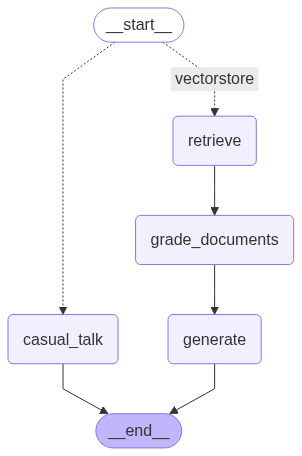

In [28]:
from IPython.display import Image, display

try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception as e:
    pass

In [29]:
# 멀티에이전트에게 질문하기
inputs = {
    "question": "서울시 자율주행 관련 계획"
}

app.invoke(inputs) # workflow 실행

--------ROUTE--------
---Routing to vectorstore---
--------RETRIEVE--------
--------GRADE DOCUMENTS--------
--------GENERATE--------


{'question': '서울시 자율주행 관련 계획',
 'generation': AIMessage(content='서울시는 자율주행 관련 계획을 단계적으로 추진하고 있습니다. 2030년까지 간선도로급 이상의 도로에서 자율주행 자동차가 운영될 수 있는 인프라 환경을 조성하고, 2040년까지 서울 전역에서 자율주행차량의 운행 환경을 구축하는 것을 목표로 하고 있습니다. 이 계획의 일환으로, 자율주행차의 수송 분담률을 10% 달성하는 것을 목표로 하고 있습니다.\n\n또한, 서울시는 도심 항공교통(UAM) 기반을 마련하고 터미널을 확충하는 계획도 포함되어 있습니다. 김포공항까지의 시범노선을 운영하고, 장기적으로 한강 및 주요 수변 공간을 중심으로 광역노선을 확보할 예정입니다. 이를 위해 UAM 인프라 확보를 위한 인센티브 및 도시계획적 지원 방안도 검토하고 있습니다.\n\n마지막으로, 서울 전역에 모빌리티 허브를 구축하여 도심 및 광역거점에서 미래 교통과 기존 교통을 연결하는 시설을 도입할 계획입니다. 이러한 허브는 교통뿐만 아니라 공공서비스, 물류, 상업 등 다양한 기능을 복합적으로 제공하는 지역 거점으로 기능할 것입니다.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 278, 'prompt_tokens': 1484, 'total_tokens': 1762, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_34a

In [31]:
# 워크플로 확인하기
iputs = {
    "question": "안녕?"
}

app.invoke(inputs)

--------ROUTE--------
---Routing to vectorstore---
--------RETRIEVE--------
--------GRADE DOCUMENTS--------
--------GENERATE--------


{'question': '서울시 자율주행 관련 계획',
 'generation': AIMessage(content='서울시는 자율주행 관련 계획을 단계적으로 추진하고 있습니다. 2030년까지 간선도로급 이상의 도로에서 자율주행 자동차가 운영될 수 있는 인프라 환경을 조성하고, 2040년까지 서울 전역에서 자율주행 차량의 운행 환경을 구축하는 것을 목표로 하고 있습니다. 이 계획의 일환으로, 자율주행 차량의 수송 분담률을 10% 달성하는 것을 목표로 하고 있습니다.\n\n또한, 서울시는 도심 항공교통(UAM) 기반을 마련하고 터미널을 확충하는 계획도 포함되어 있습니다. 김포공항까지의 시범노선을 운영하고, 장기적으로 한강 및 주요 수변 공간을 중심으로 광역노선을 확보할 예정입니다. 이를 위해 UAM 인프라 확보를 위한 인센티브 및 도시계획적 지원 방안도 검토하고 있습니다.\n\n마지막으로, 서울 전역에 모빌리티 허브를 구축하여 도심 및 광역거점에서 미래 교통과 기존 교통을 연결하는 시설을 도입할 계획입니다. 이러한 허브는 교통뿐만 아니라 공공서비스, 물류, 상업 등 다양한 기능을 복합적으로 제공하는 지역 거점으로 기능할 것입니다.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 277, 'prompt_tokens': 1484, 'total_tokens': 1761, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_

In [32]:
inputs = {
    "question": "서울시 자율주행 관련 계획"
}

for msg, meta in app.stream(inputs, stream_mode="messages"):
    print(msg.content, end='')

--------ROUTE--------
{"datasource":"---Routing to vectorstore---
vectorstore"}--------RETRIEVE--------
--------GRADE DOCUMENTS--------
{"binary_score":"yes"}{"binary_score":"yes"}{"binary_score":"no"}--------GENERATE--------
서울시는 자율주행 관련 계획을 단계적으로 추진하고 있습니다. 2030년까지 간선도로급 이상의 도로에서 자율주행 자동차가 운영될 수 있는 인프라 환경을 조성하고, 2040년까지 서울 전역에서 자율주행차량의 운행 환경을 구축하는 것을 목표로 하고 있습니다. 이 계획의 일환으로, 자율주행차의 수송 분담률을 10% 달성하는 것을 목표로 하고 있습니다.

또한, 서울시는 도심 항공교통(UAM) 기반을 마련하고, 주요 수변 공간 중심으로 광역노선을 확장하는 계획도 포함되어 있습니다. 이를 위해 UAM 시범노선을 운영하고, 모빌리티 허브를 서울 전역에 구축하여 기존 교통과 미래 교통을 연결하는 시설을 도입할 예정입니다. 이러한 계획은 서울의 교통체계를 포용적이고 효율적으로 변화시키기 위한 노력의 일환으로 볼 수 있습니다.